# Imports

In [1]:
import pandas as pd
import warnings
import sqlite3
import urllib.request
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
from branca.colormap import LinearColormap

# Load Required Data

## Load all CSV files

In [2]:
facilities_url = 'https://raw.githubusercontent.com/RollieGarcia0031/CPE-15-lec/refs/heads/main/final-project/Operation%20Blank%20Map%20-%20STUDENT%20PACKAGE/data/facilities.csv'
household_url = 'https://raw.githubusercontent.com/RollieGarcia0031/CPE-15-lec/refs/heads/main/final-project/Operation%20Blank%20Map%20-%20STUDENT%20PACKAGE/data/household_access.csv'
risk_index_url = 'https://raw.githubusercontent.com/RollieGarcia0031/CPE-15-lec/refs/heads/main/final-project/Operation%20Blank%20Map%20-%20STUDENT%20PACKAGE/data/risk_index.csv'
gjson_url = 'https://raw.githubusercontent.com/RollieGarcia0031/CPE-15-lec/refs/heads/main/final-project/Operation%20Blank%20Map%20-%20STUDENT%20PACKAGE/data/zones.geojson'

warnings.filterwarnings('ignore')

facilities_df = pd.read_csv(facilities_url)
household_df = pd.read_csv(household_url)
risk_index_df = pd.read_csv(risk_index_url)
gdf = gpd.read_file(gjson_url)

print('Loaded Facilities Rows: ', len(facilities_df))
print('Loaded Household Rows: ', len(household_df))
print('Loaded Risk Index Rows: ', len(risk_index_df))
print('Geojson  Rows: ', len(gdf))

Loaded Facilities Rows:  5
Loaded Household Rows:  13
Loaded Risk Index Rows:  13
Geojson  Rows:  12


## Load SQL file

In [3]:
sql_url = "https://raw.githubusercontent.com/RollieGarcia0031/CPE-15-lec/main/final-project/Operation%20Blank%20Map%20-%20STUDENT%20PACKAGE/data/service_requests.sqlite?raw=true"
SQL_FILENAME = "service_requests.sqlite"

urllib.request.urlretrieve(sql_url, SQL_FILENAME)
with sqlite3.connect(SQL_FILENAME) as con:
    requests = pd.read_sql_query('SELECT * FROM requests', con)

print('Requests loaded: ', len(requests))

Requests loaded:  397


## CRS Declaration

In [4]:
METRIC_CRS = "EPSG:32651"
WGS84 = "EPSG:4326"

# Problems

In [5]:
household_zone_codes = household_df['zone_code']
risk_index_zone_codes = risk_index_df['zone_code']

household_dup_mask = household_zone_codes.duplicated()
risk_index_dup_mask = risk_index_zone_codes.duplicated()

print('Household zone codes all:\t', list(household_zone_codes))
print('Household zone codes unique:\t', list(household_zone_codes.unique()))
print('Household zone codes count:\t', len(household_zone_codes))
print('zone codes unique count:\t', len(household_zone_codes.unique()))
print('Household zone codes dup:\t', sum(household_zone_codes.duplicated()))
print('duplicated zone code:\t\t',
      list(household_zone_codes[household_dup_mask]))
print()
print('Risk Index zone codes all:\t', list(risk_index_zone_codes))
print('Risk Index zone codes unique:\t', list(risk_index_zone_codes.unique()))
print('zone codes unique:\t\t', len(risk_index_zone_codes.unique()))
print('Risk Index zone codes count:\t', len(risk_index_zone_codes))
print('Risk Index zone codes dupp:\t', sum(risk_index_zone_codes.duplicated()))
print('duplicated zone codes:\t\t',
      list(risk_index_zone_codes[risk_index_dup_mask]))

print()
req_zone_code = requests['zone_code']

print('Requests zone codes unique:\t', list(req_zone_code.unique()))
print('Requests zone codes count:\t', len(req_zone_code.unique()))
print('Requests zone codes dupp:\t', sum(req_zone_code.duplicated()))

Household zone codes all:	 ['A01', 'A02', 'A-03', 'A04', 'A05', 'A06', 'A07', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
Household zone codes unique:	 ['A01', 'A02', 'A-03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
Household zone codes count:	 13
zone codes unique count:	 12
Household zone codes dup:	 1
duplicated zone code:		 ['A07']

Risk Index zone codes all:	 ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A09']
Risk Index zone codes unique:	 ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
zone codes unique:		 12
Risk Index zone codes count:	 13
Risk Index zone codes dupp:	 1
duplicated zone codes:		 ['A09']

Requests zone codes unique:	 ['A09', 'A11', 'A03', 'A05', 'A08', 'A10', 'A06', 'A02', 'A12', 'A04', 'A01', 'A-03', 'A07']
Requests zone codes count:	 13
Requests zone codes dupp:	 384


## Problem 1: `zone_code` Inconsistency
1. household data has msispeled `zone_code`
2. risk index data has duplicaeted `zone_code`
3. requests has misspelled `A03` to `A-03` 

## Problem 2: Missing Household Data
Household data has 1 record with a missing data on `household_With_access`

In [6]:
household_cols = list(household_df.columns)

display(household_df)

missing_hh_access = household_df['households_with_access'].isna().sum()
print("Missing household access record:", int(missing_hh_access))

,zone_code,total_households,households_with_access
0,A01,850,520.0
1,A02,700,238.0
2,A-03,500,228.0
3,A04,350,260.0
4,A05,460,325.0
5,A06,820,NaN
6,A07,1100,400.0
7,A07,1100,400.0
8,A08,650,150.0
9,A09,500,220.0


Missing household access record: 1


## Problem 3: Requests Duplicate
Requests has **3 duplicated rows**

In [7]:
dup_mask = requests['request_id'].duplicated(keep=False)
dup_df = requests.loc[dup_mask]
dup_df = dup_df.sort_values(by='request_id')
dup_df

,request_id,zone_code,request_type,status,requested_at
109,REQ-A01-0008,A01,training,verified,2026-09-09
331,REQ-A01-0008,A01,training,verified,2026-09-09
116,REQ-A03-0017,A03,connectivity,verified,2026-09-18
373,REQ-A03-0017,A03,connectivity,verified,2026-09-18
161,REQ-A06-0006,A06,training,open,2026-09-07
226,REQ-A06-0006,A06,training,open,2026-09-07


## Problem 4: Conflicting Count of Household
Verify if the number of `total_households` is greater then the `house`

In [8]:
miscount_mask = household_df['households_with_access'] > household_df['total_households']
print("Miscounts: ", miscount_mask.sum())
display(household_df[miscount_mask])

Miscounts:  1


,zone_code,total_households,households_with_access
11,A11,780,1220.0


## Problem 5: Requests Status
Some status `canceled` and `invalid` are inegligeble

In [9]:
status_df = pd.DataFrame(requests['status'].value_counts())
display(status_df)

,count
status,
verified,223
open,102
invalid,36
cancelled,36


## Problem 6: Duplicate `risk_index` record
zone A09 has been recorded twice in the `risk_index` dataframe

In [10]:
mask = risk_index_df['zone_code'].duplicated(keep=False)
print('Duplicated rows: ')
risk_index_df.loc[mask]

Duplicated rows: 


,zone_code,risk_score
8,A09,72
12,A09,96


# Fixes

## Create copies of dataframes

In [11]:
household_df_clean = household_df.copy()
risk_index_df_clean = risk_index_df.copy()
facilities_df_clean = facilities_df.copy()
requests_clean = requests.copy()

## Fix 1

### Fix 1.1
Replace the `zone_code` of `household_df` field with correct format

In [12]:
# Display zone codes in household_df
zone_list = list(household_df['zone_code'].unique())
print('Raw Zones:\t',", ".join(zone_list))
zone_code_map = {
    'A-03': 'A03'
}

household_df_clean['zone_code'] = household_df_clean['zone_code'].replace(zone_code_map)
print('Cleaned Zones:\t', ", ".join(list(household_df_clean['zone_code'])))

Raw Zones:	 A01, A02, A-03, A04, A05, A06, A07, A08, A09, A10, A11, A12
Cleaned Zones:	 A01, A02, A03, A04, A05, A06, A07, A07, A08, A09, A10, A11, A12


In [13]:
facilities_df_clean

,facility_id,facility_name,longitude,latitude,status
0,F01,Scenario Assistance Hub — Kalangay,121.552,14.1570,operational
1,F02,Scenario Assistance Hub — Kilib,121.570,14.1275,operational
2,F03,Scenario Assistance Hub — Nagsinamo,121.602,14.1100,operational
3,F04,Scenario Assistance Hub — Tiawe,121.595,14.0817,operational
4,F05,Scenario Assistance Hub — Kalyaat,121.530,14.1427,operational


### Fix 1.2 Duplicate Household
Drop the duplicated row of `household_df`

In [14]:
dup = household_df.duplicated(keep=False)
print('Dupilcated Row: ', dup.sum())
display(household_df[dup])
print()

# drop duplicated rows:
household_df_clean = household_df_clean.drop_duplicates()
print('Duplicated in Cleaned DF:',
      household_df_clean.duplicated().sum())
display(household_df_clean)

Dupilcated Row:  2


,zone_code,total_households,households_with_access
6,A07,1100,400.0
7,A07,1100,400.0



Duplicated in Cleaned DF: 0


,zone_code,total_households,households_with_access
0,A01,850,520.0
1,A02,700,238.0
2,A03,500,228.0
3,A04,350,260.0
4,A05,460,325.0
5,A06,820,NaN
6,A07,1100,400.0
8,A08,650,150.0
9,A09,500,220.0
10,A10,410,300.0


### Fix 1.3 Requests `zone_code` with A-03 value
Replace all A-03 with A03 in requests

Declare a reusable function to normalize zone_code inconsistencies

In [15]:
# fix the A-03 to A03 format
def normalize_zone_code(df, data_frame_name):
    print(data_frame_name, ':')
    zone_map = {
        'A-03': 'A03'
    }

    print('Raw zone_code: ',
         list(df['zone_code'].unique()))

    print('Raw zone_code: ', len(df['zone_code'].unique()))

    # Apply the fix map
    df['zone_code'] = df['zone_code'].replace(zone_map)
    print('Clean zone_code: ',
        list(df['zone_code'].unique())
    )

    print('Clean zone_code: ', len(requests_clean['zone_code'].unique()), '\n\n')

Normalize the 3 dataframes:
* requests
* household
* risk_index 

In [16]:

data_frames = [
    (requests_clean, "Request Data Frame"),
    (household_df_clean, "Household Data Frame"),
    (risk_index_df_clean, "Risk Index Data Frame")
]

for frames in data_frames:
    df, df_name = frames
    normalize_zone_code(df, df_name)

Request Data Frame :
Raw zone_code:  ['A09', 'A11', 'A03', 'A05', 'A08', 'A10', 'A06', 'A02', 'A12', 'A04', 'A01', 'A-03', 'A07']
Raw zone_code:  13
Clean zone_code:  ['A09', 'A11', 'A03', 'A05', 'A08', 'A10', 'A06', 'A02', 'A12', 'A04', 'A01', 'A07']
Clean zone_code:  12 


Household Data Frame :
Raw zone_code:  ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
Raw zone_code:  12
Clean zone_code:  ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
Clean zone_code:  12 


Risk Index Data Frame :
Raw zone_code:  ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
Raw zone_code:  12
Clean zone_code:  ['A01', 'A02', 'A03', 'A04', 'A05', 'A06', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12']
Clean zone_code:  12 




## Fix 2: Fill blank record for A06
Fill it up with a value of 350 as stated in FN-02

In [17]:
target_zone = "A06"
new_value = 350
mask = household_df_clean['zone_code'] == target_zone

household_df_clean.loc[mask, 'households_with_access'] = new_value
household_df_clean['households_with_access'] = household_df_clean['households_with_access'].astype('Int64')
print('Raw row: ')
display(
    household_df.loc[household_df['zone_code'] == target_zone]
)
print('\n')
print('Filled Row')
display(
    household_df_clean[mask]
)

Raw row: 


,zone_code,total_households,households_with_access
5,A06,820,NaN




Filled Row


,zone_code,total_households,households_with_access
5,A06,820,350


## Fix 3: Remove Duplicate Rows in `requests` df

In [18]:
# show the duplicated rows
mask = requests.duplicated(keep=False)

print("Duplicate rows: ", mask.sum())
dup_df = requests[mask]
dup_df.sort_values(by='request_id')

Duplicate rows:  6


,request_id,zone_code,request_type,status,requested_at
109,REQ-A01-0008,A01,training,verified,2026-09-09
331,REQ-A01-0008,A01,training,verified,2026-09-09
116,REQ-A03-0017,A03,connectivity,verified,2026-09-18
373,REQ-A03-0017,A03,connectivity,verified,2026-09-18
161,REQ-A06-0006,A06,training,open,2026-09-07
226,REQ-A06-0006,A06,training,open,2026-09-07


In [19]:
requests_clean = requests_clean.drop_duplicates(subset='request_id')
drop_count = len(requests) - len(requests_clean)

mask = requests_clean.duplicated(keep=False)
print('Duplicated rows:\t', mask.sum())
print('Total requests (raw):\t', len(requests))
print('Total requests (clean):\t', len(requests_clean))
print('Drop count:\t\t', drop_count)

Duplicated rows:	 0
Total requests (raw):	 397
Total requests (clean):	 394
Drop count:		 3


## Fix 4: Fill household with miscount of `household_with_access`

In [20]:
mask = household_df_clean['total_households'] < household_df_clean['households_with_access']
display(household_df_clean.loc[mask])

household_df_clean.loc[mask, 'households_with_access'] = 220
household_df_clean['households_with_access'] = household_df_clean['households_with_access'].astype('Int64')

household_df_clean[mask]

,zone_code,total_households,households_with_access
11,A11,780,1220


,zone_code,total_households,households_with_access
11,A11,780,220


## Fix 5: Remove `invalid` and `canceled` requests

In [21]:
requests_clean['status'].value_counts()

print('cleaning...')

for stat in ['invalid', 'cancelled']:
    print(stat,':\t', (requests_clean['status'] == stat).sum())

print('Total Rows: ', len(requests_clean))

mask = requests_clean['status'].isin(['invalid', 'cancelled'])
requests_clean = requests_clean[~mask]

print('\n\ndone cleaning')
print('removed:\t', mask.sum())
for stat in ['invalid', 'cancelled']:
    print(stat,':\t', (requests_clean['status'] == stat).sum())
print('Total Rows: ', len(requests_clean))

cleaning...
invalid :	 36
cancelled :	 36
Total Rows:  394


done cleaning
removed:	 72
invalid :	 0
cancelled :	 0
Total Rows:  322


## Fix 6: Remove `risk_index` duplicate row
Keep the row with 72 `risk_score`

In [22]:
dup_mask = risk_index_df_clean['zone_code'].duplicated(keep=False)
keep_mask = risk_index_df_clean['risk_score'] == 72

print("Duplicated zone_code:\t")
display(risk_index_df_clean[dup_mask])

# remove the duplicated row
risk_index_df_clean = risk_index_df_clean[~(~keep_mask & dup_mask)]

# show how much rows was removed
drop_count = len(risk_index_df) - len(risk_index_df_clean)
print("\n\nDropped Rows:\t", drop_count)

# display the currently cleaned risk index tabl
print("Cleaned risk index table: ")
risk_index_df_clean

Duplicated zone_code:	


,zone_code,risk_score
8,A09,72
12,A09,96




Dropped Rows:	 1
Cleaned risk index table: 


,zone_code,risk_score
0,A01,40
1,A02,80
2,A03,66
3,A04,25
4,A05,40
5,A06,48
6,A07,55
7,A08,77
8,A09,72
9,A10,24


# Build Analysis Table

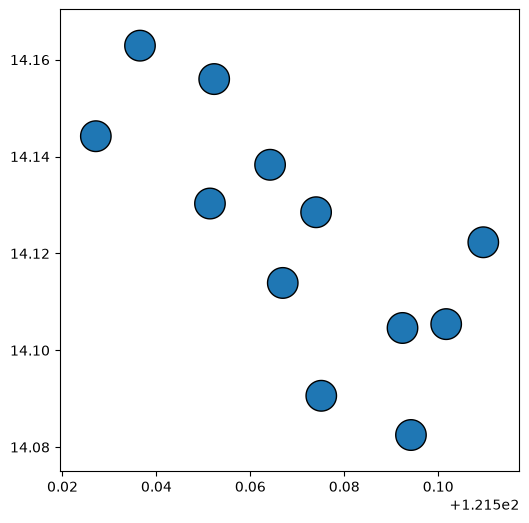

In [23]:
fig, ax = plt.subplots(figsize=(10,6))
gdf.plot(ax=ax, edgecolor="black")
plt.show()

## 1. Fix the zone_id column
Rename the zone_id column to match the zone_code column of other data frames

In [24]:
gdf = gdf.rename(columns={'zone_id': 'zone_code'})

## 2. Create a copy of household and risk_index data frames
Create a copy of household data frames with float data type for `households_with_access` and `total_households`

In [25]:
# shared column name
zone_code = 'zone_code'

# household column names
hh_total = 'total_households'
hh_access = 'households_with_access'

# risk index column names
r_score = 'risk_score'

# create a copy of household and risk_index data frame
hh_copy = household_df_clean[
    [zone_code, hh_total, hh_access]
].copy()

r_copy = risk_index_df_clean[
    [zone_code, r_score]
].copy()

hh_copy[[hh_total, hh_access]] = hh_copy[[hh_total, hh_access]].astype(float)

## 3. Create the demand data frame from requests

In [26]:
demand_sql = """
    SELECT
        CASE WHEN zone_code = 'A-03'
            THEN 'A03'
        ELSE zone_code
            END AS zone_code,
    COUNT(DISTINCT request_id) AS valid_requests
    FROM requests
    WHERE status IN ('verified', 'open')
    GROUP BY 1
    ORDER BY 1;
"""
with sqlite3.connect(SQL_FILENAME) as con:
    demand_df = pd.read_sql_query(demand_sql, con)

print(demand_df.to_string(index=False))

zone_code  valid_requests
      A01              23
      A02              29
      A03              36
      A04              14
      A05              17
      A06              32
      A07              35
      A08              28
      A09              40
      A10              11
      A11              32
      A12              25


## 4. Merge in the analysis dataframe

In [27]:
analysis = (gdf
    .merge(
        hh_copy,
        on=zone_code,
        how='left',
        validate='one_to_one'
    ).merge(
        r_copy,
        on=zone_code,
        how='left',
        validate='one_to_one'
    ).merge(
        demand_df,
        on=zone_code,
        how='left',
        validate='one_to_one'
    )
)
analysis.head(3)

,zone_code,zone_name,psgc_code,latitude,longitude,geometry_type,anchor_precision,geometry,total_households,households_with_access,risk_score,valid_requests
0,A01,Abang,0405623001,14.1303,121.5514,SIMULATED_350M_STUDY_CATCHMENT_NOT_OFFICIAL_BA...,approximate mapping reference point; not geode...,"POLYGON ((121.55464 14.13032, 121.55464 14.130...",850.0,520.0,40,23
1,A02,Aliliw,0405623002,14.1383,121.5642,SIMULATED_350M_STUDY_CATCHMENT_NOT_OFFICIAL_BA...,approximate mapping reference point; not geode...,"POLYGON ((121.56744 14.13832, 121.56744 14.138...",700.0,238.0,80,29
2,A03,Atulinao,0405623003,14.1223,121.6096,SIMULATED_350M_STUDY_CATCHMENT_NOT_OFFICIAL_BA...,approximate mapping reference point; not geode...,"POLYGON ((121.61284 14.12232, 121.61284 14.122...",500.0,228.0,66,36


## 5. Calculate service gap

In [28]:
# fill up missing valid_request data
analysis['valid_requests'] = analysis['valid_requests'].fillna(0).astype(int)

access_total_ratio = analysis[hh_access] / analysis[hh_total]
analysis['service_gap'] = 100 * (1 - access_total_ratio)

analysis[['service_gap', zone_code]]

,service_gap,zone_code
0,38.823529,A01
1,66.000000,A02
2,54.400000,A03
3,25.714286,A04
4,29.347826,A05
5,57.317073,A06
6,63.636364,A07
7,76.923077,A08
8,56.000000,A09
9,26.829268,A10


## 6. Ingtegrity Checks

In [29]:
assert (
    len(analysis) == 12
    and analysis[zone_code].is_unique
)

assert (
    analysis[
        [hh_access, hh_total, r_score]
    ].notna().all().all()
)

assert (analysis[hh_access] <= analysis[hh_total]).all()

assert analysis['service_gap'].between(0, 100).all()

print('Analysis Completed validation')

Analysis Completed validation


# Map Stuff

Facilities as points

In [30]:
fac_geometry = gpd.points_from_xy(
    facilities_df_clean['longitude'],
    facilities_df_clean['latitude']
)

fac_gdf = gpd.GeoDataFrame(
    facilities_df_clean,
    geometry=fac_geometry,
    crs=WGS84
).to_crs(METRIC_CRS)

Compute centroids

In [31]:
zones_m = analysis.to_crs(METRIC_CRS)
centroid = zones_m.geometry.centroid
centroid

0      POINT (343638.33 1562619.544)
1     POINT (345025.635 1563496.067)
2     POINT (349916.303 1561696.533)
3     POINT (343753.051 1565462.075)
4     POINT (341024.541 1564173.615)
5     POINT (346077.011 1562405.471)
6     POINT (345300.635 1560794.988)
7     POINT (348047.625 1559749.523)
8     POINT (349052.277 1559832.031)
9     POINT (342052.237 1566236.011)
10    POINT (348227.363 1557303.538)
11    POINT (346170.343 1558212.009)
dtype: geometry

## Compute nearest operational facility
Only facilities with `status = operational` are used. Get the distance as straight-line
distance from each projected zone centroid to the facility point, computed in `EPSG:32651`
so the result is in meters. This is not road distance or travel time.

In [32]:
mask = fac_gdf['status'] == 'operational'
operational_facilities = fac_gdf[mask]

nearest_ids = []
nearest_names = []
nearest_km = []

for point in centroid:
    # take distance from each point
    distances = operational_facilities.geometry.distance(point)

    # get the nearest point in listed distances
    nearest_index = distances.idxmin()

    # fill up the 3 list of nearest faciltites
    nearest_ids.append(operational_facilities.loc[nearest_index, 'facility_id'])
    nearest_names.append(operational_facilities.loc[nearest_index, 'facility_name'])
    nearest_km.append(distances.loc[nearest_index] / 1000)

# append the nearest facitility column to the analysis data frame
analysis['nearest_facility_id'] = nearest_ids
analysis['nearest_facility_name'] = nearest_names
analysis['nearest_km'] = nearest_km

analysis[['zone_code', 'nearest_facility_id', 'nearest_facility_name', 'nearest_km']]
analysis.head(3)

,zone_code,zone_name,psgc_code,latitude,longitude,geometry_type,anchor_precision,geometry,total_households,households_with_access,risk_score,valid_requests,service_gap,nearest_facility_id,nearest_facility_name,nearest_km
0,A01,Abang,0405623001,14.1303,121.5514,SIMULATED_350M_STUDY_CATCHMENT_NOT_OFFICIAL_BA...,approximate mapping reference point; not geode...,"POLYGON ((121.55464 14.13032, 121.55464 14.130...",850.0,520.0,40,23,38.823529,F02,Scenario Assistance Hub — Kilib,2.031854
1,A02,Aliliw,0405623002,14.1383,121.5642,SIMULATED_350M_STUDY_CATCHMENT_NOT_OFFICIAL_BA...,approximate mapping reference point; not geode...,"POLYGON ((121.56744 14.13832, 121.56744 14.138...",700.0,238.0,80,29,66.000000,F02,Scenario Assistance Hub — Kilib,1.348933
2,A03,Atulinao,0405623003,14.1223,121.6096,SIMULATED_350M_STUDY_CATCHMENT_NOT_OFFICIAL_BA...,approximate mapping reference point; not geode...,"POLYGON ((121.61284 14.12232, 121.61284 14.122...",500.0,228.0,66,36,54.400000,F03,Scenario Assistance Hub — Nagsinamo,1.588973


# Scoring

## Calculate distance and demand scores
`distance_score` = 100 x nearest distance / maximum zone distance.

`demand_score` = 100 x valid requests / maximum zone valid requests.

Both denominators come from the same twelve-zone scenario. If a denominator is zero,
the component score is zero.

In [33]:
max_distance_km = analysis['nearest_km'].max()
max_requests = analysis['valid_requests'].max()

analysis['distance_score'] = (
    0 if max_distance_km == 0
    else 100 * analysis['nearest_km'] / max_distance_km
)
analysis['demand_score'] = (
    0 if max_requests == 0 else 100 * analysis['valid_requests'] / max_requests
)

analysis[['zone_code', 'nearest_km', 'distance_score', 'valid_requests', 'demand_score']]

,zone_code,nearest_km,distance_score,valid_requests,demand_score
0,A01,2.031854,85.962130,23,57.5
1,A02,1.348933,57.069611,29,72.5
2,A03,1.588973,67.225063,36,90.0
3,A04,0.115273,4.876862,14,35.0
4,A05,0.354337,14.991010,17,42.5
5,A06,0.445795,18.860345,32,80.0
6,A07,1.541330,65.209391,35,87.5
7,A08,1.196349,50.614228,28,70.0
8,A09,0.509915,21.573089,40,100.0
9,A10,1.796010,75.984219,11,27.5


## Calculate priority and rank
$Priority = \left(0.45 \times service gap\right) + \left(0.25 \times risk\right) + 0.20 \times distance + 0.10 \times demand.$

This formula was provided by the student_casefile of sir Ranj

Sort by priority descending, then by `zone_code` ascending for exact ties.

In [34]:
# create priority column in data frame
analysis['priority'] = (
    0.45 * analysis['service_gap']
    + 0.25 * analysis['risk_score']
    + 0.20 * analysis['distance_score']
    + 0.10 * analysis['demand_score']
)

# rearrange the rows from high -> low priority
analysis = analysis.sort_values(
    by=['priority', 'zone_code'],
    ascending=[False, True]
).reset_index(drop=True)

analysis['rank'] = range(1, len(analysis) + 1)

analysis[[
    'rank', 'zone_code', 'zone_name', 'service_gap', 'risk_score',
    'nearest_km', 'distance_score', 'valid_requests',
    'demand_score', 'priority'
]]

,rank,zone_code,zone_name,service_gap,risk_score,nearest_km,distance_score,valid_requests,demand_score,priority
0,1,A08,Malupak,76.923077,77,1.196349,50.614228,28,70.0,70.988230
1,2,A02,Aliliw,66.000000,80,1.348933,57.069611,29,72.5,68.363922
2,3,A07,Kulapi,63.636364,55,1.541330,65.209391,35,87.5,64.178242
3,4,A03,Atulinao,54.400000,66,1.588973,67.225063,36,90.0,63.425013
4,5,A11,Tiawe,71.794872,72,0.123674,5.232294,32,80.0,59.354151
5,6,A09,Nagsinamo,56.000000,72,0.509915,21.573089,40,100.0,57.514618
6,7,A12,Tinamnan,37.500000,40,2.363662,100.000000,25,62.5,53.125000
7,8,A01,Abang,38.823529,40,2.031854,85.962130,23,57.5,50.413014
8,9,A06,Kilib,57.317073,48,0.445795,18.860345,32,80.0,49.564752
9,10,A10,Nalunao,26.829268,24,1.796010,75.984219,11,27.5,36.020015


## Original top three

In [35]:
top_three = analysis.head(3)

print('Maximum zone distance (km):\t', round(max_distance_km, 4))
print('Maximum valid requests:\t\t', int(max_requests))
print()
print('Original top three:')
for row in top_three.itertuples():
    print(f'\t{row.rank}. {row.zone_code} - {row.zone_name}: {row.priority:.2f}')

Maximum zone distance (km):	 2.3637
Maximum valid requests:		 40

Original top three:
	1. A08 - Malupak: 70.99
	2. A02 - Aliliw: 68.36
	3. A07 - Kulapi: 64.18


# Charts
## Chart 1: Priority ranking
Bar length is the final priority score. The original top three are highlighted.

I used horizontal bar graph as it was hard to fit the zone names po 😭

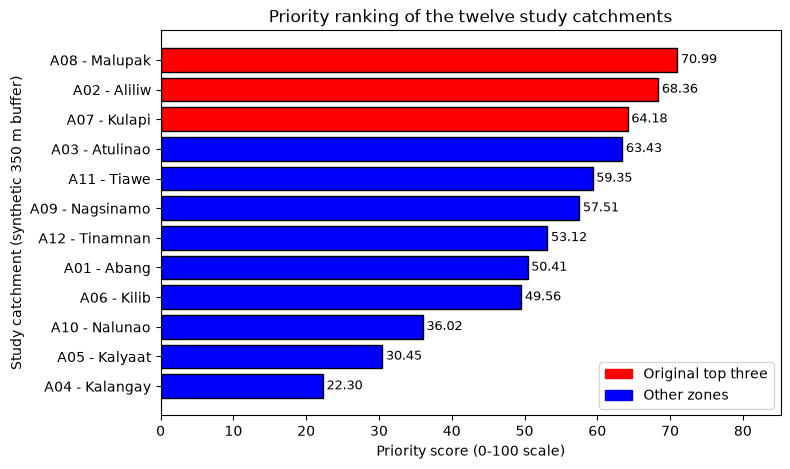

In [36]:
chart = analysis.sort_values('priority', ascending=True)
top_color = 'red'
other_color = 'blue'

colors = [top_color if rank <= 3 else other_color for rank in chart['rank']]

# construct the hozizontal graph
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.barh(
    chart['zone_code'] + ' - ' + chart['zone_name'],
    chart['priority'],
    color=colors,
    edgecolor='black'
)

# place the precise values on each bar
for bar, value in zip(bars, chart['priority']):
    ax.text(value + 0.5, bar.get_y() + bar.get_height() / 2,
            f'{value:.2f}', va='center', fontsize=9)

ax.set_xlim(0, chart['priority'].max() * 1.20) # add small margin to the right
ax.set_xlabel('Priority score (0-100 scale)')
ax.set_ylabel('Study catchment (synthetic 350 m buffer)')
ax.set_title('Priority ranking of the twelve study catchments', loc='center')

# create legend for 2 color code
legend_handles = [
    plt.Rectangle(
        (0, 0), 1, 1,
        color=top_color,
        label='Original top three'
    ),

    plt.Rectangle(
        (0, 0), 1, 1,
        color=other_color,
        label='Other zones'
    )
]

ax.legend(
    handles=legend_handles,
    loc='lower right'
)

plt.show()

## Chart 2: Weighted contributions
show which component drives each priority score.
The stacked bars add up to the final priority.

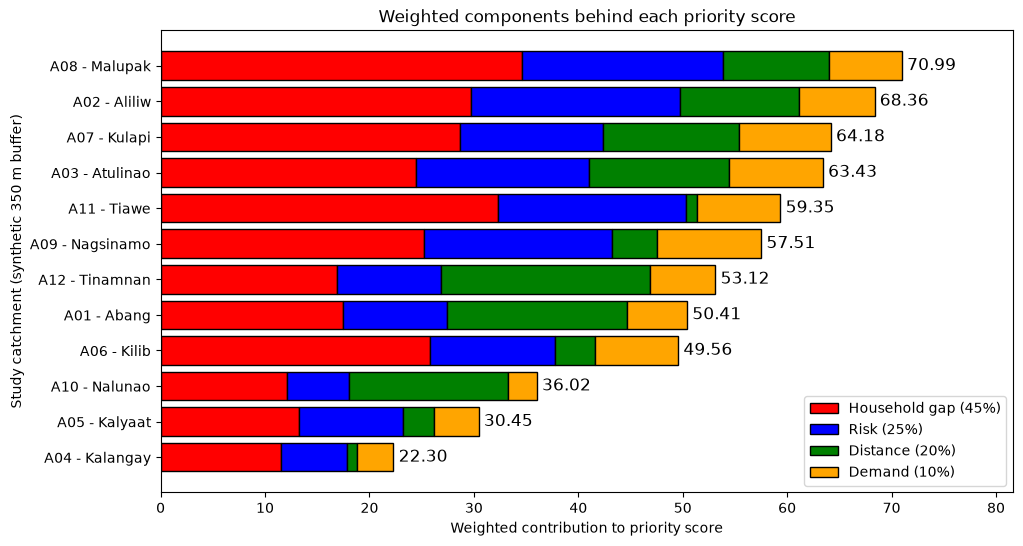

In [37]:
# add column to see how priority add ups
analysis['gap_component'] = 0.45 * analysis['service_gap']
analysis['risk_component'] = 0.25 * analysis['risk_score']
analysis['distance_component'] = 0.20 * analysis['distance_score']
analysis['demand_component'] = 0.10 * analysis['demand_score']

chart = analysis.sort_values('priority', ascending=True)
labels = chart['zone_code'] + ' - ' + chart['zone_name']
left = [0] * len(chart)

hhold_color = 'red'
risk_color = 'blue'
distance_color = 'green'
demand_color = 'orange'

components = [
    ('gap_component', 'Household gap (45%)', hhold_color),
    ('risk_component', 'Risk (25%)', risk_color),
    ('distance_component', 'Distance (20%)', distance_color),
    ('demand_component', 'Demand (10%)', demand_color)
]

fig, ax = plt.subplots(figsize=(11, 6))

for column, label, color in components:
    values = list(chart[column])
    ax.barh(labels, values, left=left, color=color, edgecolor='black', label=label)
    left = [base + value for base, value in zip(left, values)]

for i, total in enumerate(chart['priority']):
    ax.text(total + 0.5, i, f'{total:.2f}', va='center', fontsize=12)

ax.set_xlim(0, chart['priority'].max() * 1.15)
ax.set_xlabel('Weighted contribution to priority score')
ax.set_ylabel('Study catchment (synthetic 350 m buffer)')
ax.set_title('Weighted components behind each priority score', loc='center')
ax.legend(loc='lower right')
plt.show()

The household service gap (45%) is the largest contributor for most zones. A08, A02 and A07
lead because their gaps are large, and A02 also has the highest validated risk score.
Zones near an operational facility (A04, A05, A11) receive little distance credit even when
their service gap is large.

# Interactive Map
The zones are coloured by priority score. Facilities are plotted as blue dots.

This map includes tooltips, popups, a layer control, a legend and a simulated-data disclaimer.

In [38]:
map_gdf = analysis.to_crs(WGS84)
minx, miny, maxx, maxy  = map_gdf.total_bounds
center = [(miny + maxy) / 2, (minx + maxx) / 2]

cmap = LinearColormap(
    colors=['yellow', 'orange', 'red'],
    vmin=map_gdf['priority'].min(),
    vmax=map_gdf['priority'].max(),
    caption='Simulated priority score'
)

CARTO_KEY = 'cb1_5byu_1_936b404e09aebbe05f5b6af8'

priority_map = folium.Map(
    location=center, zoom_start=12, tiles=None, control_scale=True
)

folium.TileLayer(
    tiles=f"https://basemaps.cartocdn.com/rastertiles/voyager/{{z}}/{{x}}/{{y}}.png?key={CARTO_KEY}",
    attr='&copy; OpenStreetMap contributors &copy; CARTO',
    name='CARTO Voyager',
    max_zoom=20,
).add_to(priority_map)


def zone_style(feature):
    return {
        'fillColor': cmap(feature['properties']['priority']),
        'color': 'black',
        'weight': 2,
        'fillOpacity': 0.7
    }


zone_layer = folium.FeatureGroup(name='Study catchments (synthetic)')

folium.GeoJson(
    map_gdf.to_json(),
    style_function=zone_style,
    tooltip=folium.GeoJsonTooltip(
        fields=['zone_name', 'zone_code', 'priority', 'rank'],
        aliases=['Barangay', 'Zone', 'Priority', 'Rank']
    ),
    popup=folium.GeoJsonPopup(
        fields=['zone_name', 'zone_code', 'total_households', 'households_with_access',
                'service_gap', 'risk_score', 'valid_requests', 'nearest_facility_id',
                'nearest_km', 'distance_score', 'demand_score', 'priority', 'rank'],
        aliases=['Barangay', 'Zone', 'Total households', 'Households with access',
                 'Service gap (%)', 'Risk score', 'Valid requests', 'Nearest facility',
                 'Distance (km)', 'Distance score', 'Demand score', 'Priority', 'Rank']
    )
).add_to(zone_layer)
zone_layer.add_to(priority_map)

facility_layer = folium.FeatureGroup(name='Operational facilities (simulated)')
for row in facilities_df_clean.itertuples():
    folium.CircleMarker(
        location=[row.latitude, row.longitude],
        radius=7, color='black', weight=2,
        fill=True, fill_color='blue', fill_opacity=0.9,
        tooltip=f'{row.facility_id} - {row.facility_name}',
        popup=folium.Popup(
            f'<b>{row.facility_name}</b><br>'
            f'Facility ID: {row.facility_id}<br>'
            f'Status: {row.status}<br>'
            f'Coordinates: {row.latitude}, {row.longitude}',
            max_width=300
        )
    ).add_to(facility_layer)
facility_layer.add_to(priority_map)

legend_html = '''
<div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999; font-size: 12px;
            background: white; padding: 10px; border: 1px solid #444; border-radius: 5px;"
>
  <b>LEGEND</b><br>
  Priority Indication (light = low, dark = high)<br>
  <span style="color:blue;">&#9679;</span> Operational assistance facility<br>
</div>
'''

priority_map.get_root().html.add_child(folium.Element(legend_html))

title_html = '''
<div style="position: fixed; top: 5px; left: 50px; z-index: 9999; font-size: 1.5rem;
            background: white; padding: 2px 12px; border: 1px solid black; border-radius: 0.75em;">
  <b>Operation Blank Map - Lucban, Quezon</b>
</div>
'''

priority_map.get_root().html.add_child(folium.Element(title_html))

cmap.add_to(priority_map)
folium.LayerControl(collapsed=False).add_to(priority_map)
priority_map

# Export
Save the map as a standalone HTML file and the twelve-zone table as a CSV.

In [39]:
map_filename = 'CPE15_24-000455_FINAL_MAP.html'
csv_filename = 'CPE15_24-000455_PROCESSED.csv'

priority_map.save(map_filename)

final_columns = [
    'zone_code', 'zone_name', 'psgc_code', 'total_households',
    'households_with_access', 'service_gap', 'risk_score', 'valid_requests',
    'nearest_facility_id', 'nearest_facility_name', 'nearest_km',
    'distance_score', 'demand_score', 'priority', 'rank'
]
processed = analysis[final_columns].sort_values('rank')
processed.to_csv(csv_filename, index=False)

print('Saved map:', map_filename)
print('Saved CSV:', csv_filename)
print('Processed rows:', len(processed))
processed

Saved map: CPE15_24-000455_FINAL_MAP.html
Saved CSV: CPE15_24-000455_PROCESSED.csv
Processed rows: 12


,zone_code,zone_name,psgc_code,total_households,households_with_access,service_gap,risk_score,valid_requests,nearest_facility_id,nearest_facility_name,nearest_km,distance_score,demand_score,priority,rank
0,A08,Malupak,0405623022,650.0,150.0,76.923077,77,28,F03,Scenario Assistance Hub — Nagsinamo,1.196349,50.614228,70.0,70.988230,1
1,A02,Aliliw,0405623002,700.0,238.0,66.000000,80,29,F02,Scenario Assistance Hub — Kilib,1.348933,57.069611,72.5,68.363922,2
2,A07,Kulapi,0405623020,1100.0,400.0,63.636364,55,35,F02,Scenario Assistance Hub — Kilib,1.541330,65.209391,87.5,64.178242,3
3,A03,Atulinao,0405623003,500.0,228.0,54.400000,66,36,F03,Scenario Assistance Hub — Nagsinamo,1.588973,67.225063,90.0,63.425013,4
4,A11,Tiawe,0405623031,780.0,220.0,71.794872,72,32,F04,Scenario Assistance Hub — Tiawe,0.123674,5.232294,80.0,59.354151,5
5,A09,Nagsinamo,0405623025,500.0,220.0,56.000000,72,40,F03,Scenario Assistance Hub — Nagsinamo,0.509915,21.573089,100.0,57.514618,6
6,A12,Tinamnan,0405623032,1200.0,750.0,37.500000,40,25,F04,Scenario Assistance Hub — Tiawe,2.363662,100.000000,62.5,53.125000,7
7,A01,Abang,0405623001,850.0,520.0,38.823529,40,23,F02,Scenario Assistance Hub — Kilib,2.031854,85.962130,57.5,50.413014,8
8,A06,Kilib,0405623019,820.0,350.0,57.317073,48,32,F02,Scenario Assistance Hub — Kilib,0.445795,18.860345,80.0,49.564752,9
9,A10,Nalunao,0405623026,410.0,300.0,26.829268,24,11,F01,Scenario Assistance Hub — Kalangay,1.796010,75.984219,27.5,36.020015,10


# Result
The top three zones priority  are the  **A08 (Malupak)**, **A02 (Aliliw)** and **A07 (Kulapi)**.

A03 (Atulinao) is close to the top 3 in the list, and almost become the top thre. The full ranked table, the two charts and the interactive
map above, show the evidence behind these ranks.